# Lockheed Martin - DCF valuation

A discounted cash flow valuation of Lockheed Martin (NYSE: LMT) built from its 10-K filings.

- The historical figures (2021 to 2025) come from the 10-K, through the SEC EDGAR API.
- The beta is estimated with a linear regression of LMT monthly returns on the S&P 500.
- The valuation date is **31 December 2025**, the date of the last 10-K balance sheet. The risk-free rate, the beta and the share price are all taken at that date so that everything is consistent.

All the data is in the `data/` folder. `get_data.py` is the script that downloaded it.

## 1. Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.1f}".format

# 10-K figures, in $ millions (shares in millions)
fin = pd.read_csv("data/lmt_10k.csv", index_col="year")

# Month-end prices: LMT (dividend adjusted) and the S&P 500 total return index
prices = pd.read_csv("data/monthly_prices.csv", index_col="month")

fin.T

year,2021,2022,2023,2024,2025
revenue,"67,044.0","65,984.0","67,571.0","71,043.0","75,048.0"
ebit,"9,123.0","8,348.0","8,507.0","7,013.0","7,731.0"
pretax_income,"7,550.0","6,680.0","8,098.0","6,220.0","5,922.0"
income_tax,"1,235.0",948.0,"1,178.0",884.0,905.0
interest_expense,569.0,623.0,916.0,"1,036.0","1,118.0"
depreciation_amortization,"1,364.0","1,404.0","1,430.0","1,559.0","1,687.0"
capex,"1,522.0","1,670.0","1,691.0","1,685.0","1,649.0"
receivables,"1,963.0","2,505.0","2,132.0","2,351.0","3,901.0"
contract_assets,"10,579.0","12,318.0","13,183.0","12,957.0","13,001.0"
inventories,"2,981.0","3,088.0","3,132.0","3,474.0","3,524.0"


## 2. Inputs

In [2]:
# Market data at 31 December 2025
RISK_FREE_RATE = 0.0418    # 10-year US Treasury yield (FRED, DGS10, 31/12/2025)
SHARE_PRICE = 483.67       # LMT closing price on 31/12/2025
MARKET_PREMIUM = 0.045     # equity risk premium (assumption)
CREDIT_SPREAD = 0.010      # spread over Treasuries for an A- rated issuer (assumption)

# Forecast assumptions
FORECAST_YEARS = [2026, 2027, 2028, 2029, 2030]
REVENUE_GROWTH = [0.05, 0.045, 0.04, 0.035, 0.03]   # assumption, see README

# Terminal value
TERMINAL_GROWTH = 0.02     # perpetual growth rate
RONIC_SPREAD = 0.02        # return on new capital = WACC + this spread

## 3. Historical analysis

Working capital for Lockheed Martin is mostly contract balances: contract assets (work done but not yet billed) minus contract liabilities (advances received from customers).

```
NWC = Receivables + Contract assets + Inventories - Payables - Contract liabilities
```

In [3]:
hist = pd.DataFrame(index=fin.index)
hist["Revenue growth"] = fin["revenue"].pct_change()
hist["EBIT margin"] = fin["ebit"] / fin["revenue"]
hist["Tax rate"] = fin["income_tax"] / fin["pretax_income"]
hist["D&A % revenue"] = fin["depreciation_amortization"] / fin["revenue"]
hist["CapEx % revenue"] = fin["capex"] / fin["revenue"]

fin["nwc"] = (fin["receivables"] + fin["contract_assets"] + fin["inventories"]
              - fin["payables"] - fin["contract_liabilities"])
hist["NWC % revenue"] = fin["nwc"] / fin["revenue"]

hist.loc["Average"] = hist.mean()
(hist * 100).round(1)

,Revenue growth,EBIT margin,Tax rate,D&A % revenue,CapEx % revenue,NWC % revenue
year,,,,,,
2021,NaN,13.6,16.4,2.0,2.3,9.9
2022,-1.6,12.7,14.2,2.1,2.5,11.1
2023,2.4,12.6,14.5,2.1,2.5,10.3
2024,5.1,9.9,14.2,2.2,2.4,9.5
2025,5.6,10.3,15.3,2.2,2.2,7.1
Average,2.9,11.8,14.9,2.1,2.4,9.6


In [4]:
# The forecast uses the 5-year averages, except for working capital:
# NWC fell to 7.1% of revenue in 2025, and going back to the 9.6% average
# would create a large cash outflow in 2026 that the 10-K does not support.
EBIT_MARGIN = hist.loc["Average", "EBIT margin"]
TAX_RATE = hist.loc["Average", "Tax rate"]
DA_PCT = hist.loc["Average", "D&A % revenue"]
CAPEX_PCT = hist.loc["Average", "CapEx % revenue"]
NWC_PCT = hist.loc[2025, "NWC % revenue"]

print(f"EBIT margin      {EBIT_MARGIN:.2%}")
print(f"Tax rate         {TAX_RATE:.2%}")
print(f"D&A % revenue    {DA_PCT:.2%}")
print(f"CapEx % revenue  {CAPEX_PCT:.2%}")
print(f"NWC % revenue    {NWC_PCT:.2%}")

EBIT margin      11.80%
Tax rate         14.92%
D&A % revenue    2.14%
CapEx % revenue  2.37%
NWC % revenue    7.14%


## 4. Beta: linear regression

Beta is the slope of the regression of LMT monthly returns on the S&P 500 monthly returns, over 5 years (60 months, January 2021 to December 2025).

```
LMT return = alpha + beta x S&P 500 return + error
beta = Covariance(LMT, S&P 500) / Variance(S&P 500)
```

In [5]:
returns = prices.pct_change().dropna()
lmt = returns["lmt"]
market = returns["sp500_total_return"]

beta_raw = lmt.cov(market) / market.var()
alpha = lmt.mean() - beta_raw * market.mean()
r_squared = lmt.corr(market) ** 2

print(f"Number of months   {len(returns)}")
print(f"Raw beta           {beta_raw:.2f}")
print(f"Alpha (monthly)    {alpha:.2%}")
print(f"R squared          {r_squared:.1%}")

Number of months   60
Raw beta           0.24
Alpha (monthly)    0.65%
R squared          2.6%


In [6]:
# Check with numpy's least squares fit: the slope must be the same
slope, intercept = np.polyfit(market, lmt, 1)
print(f"Slope with np.polyfit   {slope:.2f}")

Slope with np.polyfit   0.24


The R squared is very low: the S&P 500 explains less than 3% of LMT's monthly moves. Defense stocks depend on government budgets and contracts more than on the economic cycle, so the raw beta is both low and imprecise.

To correct for this, I use the **Blume adjustment**, the one Bloomberg applies: estimated betas tend to move back toward 1 over time, so the adjusted beta gives two thirds of the weight to the regression and one third to 1.

In [7]:
beta = 0.67 * beta_raw + 0.33 * 1.0
print(f"Adjusted beta (Blume)   {beta:.2f}")

Adjusted beta (Blume)   0.49


## 5. Cost of capital (WACC)

In [8]:
cost_of_equity = RISK_FREE_RATE + beta * MARKET_PREMIUM            # CAPM
cost_of_debt = RISK_FREE_RATE + CREDIT_SPREAD
after_tax_cost_of_debt = cost_of_debt * (1 - TAX_RATE)

# Check: interest paid in 2025 / average debt of 2024 and 2025
interest_rate_10k = fin.loc[2025, "interest_expense"] / fin.loc[[2024, 2025], "total_debt"].mean()

# Weights at market value for equity, book value for debt
market_cap = SHARE_PRICE * fin.loc[2025, "shares_outstanding"]
debt = fin.loc[2025, "total_debt"]
weight_equity = market_cap / (market_cap + debt)
weight_debt = debt / (market_cap + debt)

WACC = weight_equity * cost_of_equity + weight_debt * after_tax_cost_of_debt

print(f"Cost of equity          {cost_of_equity:.2%}")
print(f"Cost of debt            {cost_of_debt:.2%}   (10-K interest / debt: {interest_rate_10k:.2%})")
print(f"Market cap              ${market_cap:,.0f}m")
print(f"Debt                    ${debt:,.0f}m")
print(f"Weight of equity        {weight_equity:.1%}")
print(f"Weight of debt          {weight_debt:.1%}")
print(f"WACC                    {WACC:.2%}")

Cost of equity          6.40%
Cost of debt            5.18%   (10-K interest / debt: 5.33%)
Market cap              $110,760m
Debt                    $21,700m
Weight of equity        83.6%
Weight of debt          16.4%
WACC                    6.07%


## 6. Free cash flow forecast

```
NOPAT = EBIT x (1 - tax rate)
FCF   = NOPAT + D&A - CapEx - Change in NWC
```

In [9]:
df = pd.DataFrame(index=FORECAST_YEARS)

revenue = []
last_revenue = fin.loc[2025, "revenue"]
for growth in REVENUE_GROWTH:
    last_revenue = last_revenue * (1 + growth)
    revenue.append(last_revenue)

df["Revenue"] = revenue
df["EBIT"] = df["Revenue"] * EBIT_MARGIN
df["Taxes"] = df["EBIT"] * TAX_RATE
df["NOPAT"] = df["EBIT"] - df["Taxes"]
df["D&A"] = df["Revenue"] * DA_PCT
df["CapEx"] = df["Revenue"] * CAPEX_PCT
df["NWC"] = df["Revenue"] * NWC_PCT
df["Change in NWC"] = df["NWC"].diff()
df.loc[2026, "Change in NWC"] = df.loc[2026, "NWC"] - fin.loc[2025, "nwc"]
df["FCF"] = df["NOPAT"] + df["D&A"] - df["CapEx"] - df["Change in NWC"]

df.T

,2026,2027,2028,2029,2030
Revenue,"78,800.4","82,346.4","85,640.3","88,637.7","91,296.8"
EBIT,"9,301.9","9,720.4","10,109.3","10,463.1","10,777.0"
Taxes,"1,387.7","1,450.1","1,508.1","1,560.9","1,607.7"
NOPAT,"7,914.2","8,270.3","8,601.2","8,902.2","9,169.3"
D&A,"1,689.6","1,765.7","1,836.3","1,900.6","1,957.6"
CapEx,"1,871.1","1,955.3","2,033.6","2,104.7","2,167.9"
NWC,"5,623.8","5,876.9","6,111.9","6,325.9","6,515.6"
Change in NWC,267.8,253.1,235.1,213.9,189.8
FCF,"7,464.9","7,827.6","8,168.8","8,484.1","8,769.2"


## 7. Terminal value

After 2030 the company grows at `g` forever. To grow, it must reinvest part of its NOPAT, and the share it reinvests depends on the return it earns on that new capital (RONIC):

```
Reinvestment rate = g / RONIC
Terminal FCF      = NOPAT 2030 x (1 + g) x (1 - g / RONIC)
Terminal value    = Terminal FCF / (WACC - g)          [Gordon Growth]
```

In [10]:
terminal_ronic = WACC + RONIC_SPREAD
reinvestment_rate = TERMINAL_GROWTH / terminal_ronic

terminal_nopat = df.loc[2030, "NOPAT"] * (1 + TERMINAL_GROWTH)
terminal_fcf = terminal_nopat * (1 - reinvestment_rate)
terminal_value = terminal_fcf / (WACC - TERMINAL_GROWTH)

print(f"Terminal RONIC        {terminal_ronic:.2%}")
print(f"Reinvestment rate     {reinvestment_rate:.1%}")
print(f"Terminal FCF          ${terminal_fcf:,.0f}m")
print(f"Terminal value        ${terminal_value:,.0f}m")

Terminal RONIC        8.07%
Reinvestment rate     24.8%
Terminal FCF          $7,035m
Terminal value        $172,821m


## 8. Discounting and enterprise value

Cash flows come in during the year, not all on 31 December, so they are discounted at mid-year (year 1 at 0.5, year 2 at 1.5, ...). The terminal value is discounted from the end of 2030 (5 years).

In [11]:
df["Period"] = [0.5, 1.5, 2.5, 3.5, 4.5]
df["Discount factor"] = 1 / (1 + WACC) ** df["Period"]
df["PV of FCF"] = df["FCF"] * df["Discount factor"]

pv_fcf = df["PV of FCF"].sum()
pv_terminal = terminal_value / (1 + WACC) ** 5
enterprise_value = pv_fcf + pv_terminal

print(f"PV of FCF 2026-2030      ${pv_fcf:,.0f}m")
print(f"PV of terminal value     ${pv_terminal:,.0f}m")
print(f"Enterprise value         ${enterprise_value:,.0f}m")
print(f"Terminal value % of EV   {pv_terminal / enterprise_value:.1%}")

PV of FCF 2026-2030      $35,092m
PV of terminal value     $128,713m
Enterprise value         $163,805m
Terminal value % of EV   78.6%


## 9. From enterprise value to share price

The pension deficit is treated as debt: Lockheed Martin will have to fund it with cash. Under US GAAP, operating lease payments are already in EBIT, so lease liabilities are not deducted (that would count them twice).

In [12]:
cash = fin.loc[2025, "cash"]
pension = fin.loc[2025, "pension_liability"]
shares = fin.loc[2025, "shares_outstanding"]

equity_value = enterprise_value - debt + cash - pension
price_per_share = equity_value / shares
upside = price_per_share / SHARE_PRICE - 1

print(f"Enterprise value          ${enterprise_value:,.0f}m")
print(f"- Debt                    ${debt:,.0f}m")
print(f"+ Cash                    ${cash:,.0f}m")
print(f"- Pension deficit         ${pension:,.0f}m")
print(f"= Equity value            ${equity_value:,.0f}m")
print(f"Shares                    {shares:,.0f}m")
print()
print(f"Implied share price       ${price_per_share:,.2f}")
print(f"Share price 31/12/2025    ${SHARE_PRICE:,.2f}")
print(f"Upside                    {upside:.1%}")

Enterprise value          $163,805m
- Debt                    $21,700m
+ Cash                    $4,121m
- Pension deficit         $3,915m
= Equity value            $142,311m
Shares                    229m

Implied share price       $621.45
Share price 31/12/2025    $483.67
Upside                    28.5%


## 10. Sensitivity analysis

The same calculation as above, written as one function so it can be run with other inputs.

In [13]:
def share_price(wacc, g, ebit_margin=EBIT_MARGIN, growth_shift=0.0):
    revenue = fin.loc[2025, "revenue"]
    nwc_before = fin.loc[2025, "nwc"]
    pv_fcf = 0
    for year in range(5):
        revenue = revenue * (1 + REVENUE_GROWTH[year] + growth_shift)
        nopat = revenue * ebit_margin * (1 - TAX_RATE)
        nwc = revenue * NWC_PCT
        fcf = nopat + revenue * DA_PCT - revenue * CAPEX_PCT - (nwc - nwc_before)
        nwc_before = nwc
        pv_fcf += fcf / (1 + wacc) ** (year + 0.5)

    terminal_fcf = nopat * (1 + g) * (1 - g / (wacc + RONIC_SPREAD))
    pv_terminal = terminal_fcf / (wacc - g) / (1 + wacc) ** 5

    equity = pv_fcf + pv_terminal - debt + cash - pension
    return equity / shares


# Check: the function gives the same price as the step-by-step model
print(f"${share_price(WACC, TERMINAL_GROWTH):,.2f}")

$621.45


In [14]:
wacc_range = [WACC - 0.01, WACC - 0.005, WACC, WACC + 0.005, WACC + 0.01]
g_range = [0.01, 0.015, 0.02, 0.025, 0.03]

table = pd.DataFrame(index=[f"WACC {w:.2%}" for w in wacc_range],
                     columns=[f"g {g:.1%}" for g in g_range], dtype=float)
for w in wacc_range:
    for g in g_range:
        table.loc[f"WACC {w:.2%}", f"g {g:.1%}"] = share_price(w, g)

print("Implied share price ($): WACC x terminal growth")
table.round(0)

Implied share price ($): WACC x terminal growth


,g 1.0%,g 1.5%,g 2.0%,g 2.5%,g 3.0%
WACC 5.07%,729.0,763.0,808.0,869.0,958.0
WACC 5.57%,647.0,672.0,703.0,744.0,800.0
WACC 6.07%,580.0,599.0,621.0,650.0,688.0
WACC 6.57%,524.0,539.0,556.0,577.0,604.0
WACC 7.07%,477.0,489.0,502.0,518.0,538.0


In [15]:
margin_range = [0.09, 0.10, 0.11, 0.12, 0.13, 0.14]
shift_range = [-0.02, -0.01, 0.0, 0.01, 0.02]

table2 = pd.DataFrame(index=[f"EBIT margin {m:.0%}" for m in margin_range],
                      columns=[f"growth {s:+.0%}" for s in shift_range], dtype=float)
for m in margin_range:
    for s in shift_range:
        table2.loc[f"EBIT margin {m:.0%}", f"growth {s:+.0%}"] = share_price(WACC, TERMINAL_GROWTH, m, s)

print("Implied share price ($): EBIT margin x change in yearly revenue growth")
table2.round(0)

Implied share price ($): EBIT margin x change in yearly revenue growth


,growth -2%,growth -1%,growth +0%,growth +1%,growth +2%
EBIT margin 9%,406.0,427.0,450.0,473.0,497.0
EBIT margin 10%,462.0,486.0,511.0,537.0,564.0
EBIT margin 11%,518.0,544.0,572.0,601.0,631.0
EBIT margin 12%,574.0,603.0,633.0,665.0,697.0
EBIT margin 13%,630.0,662.0,695.0,729.0,764.0
EBIT margin 14%,686.0,720.0,756.0,793.0,831.0


## 11. Charts

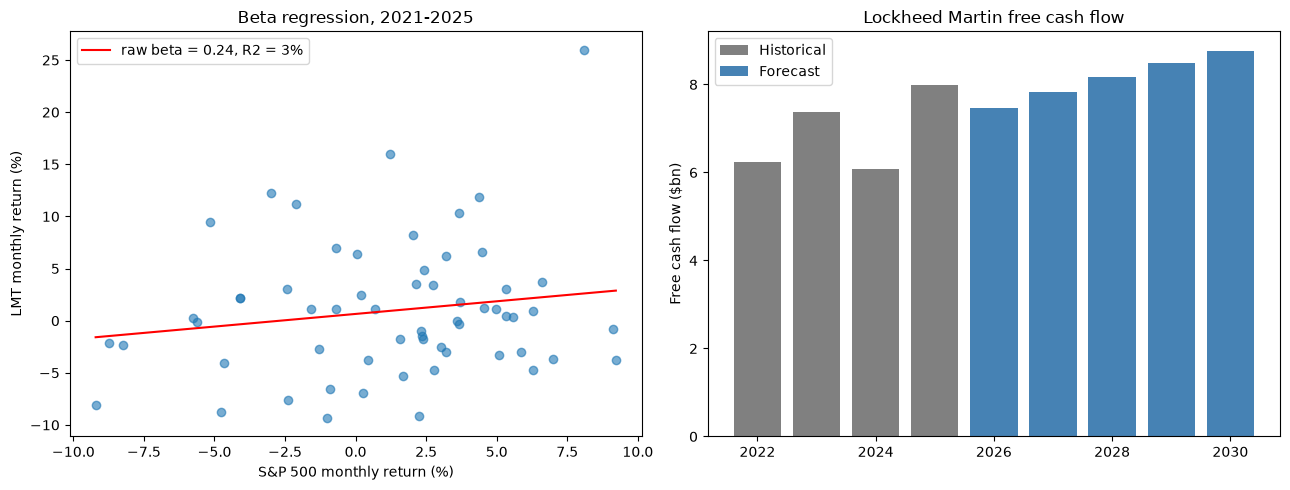

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left: the beta regression
ax1.scatter(market * 100, lmt * 100, alpha=0.6)
x = np.linspace(market.min(), market.max(), 50)
ax1.plot(x * 100, (alpha + beta_raw * x) * 100, color="red",
         label=f"raw beta = {beta_raw:.2f}, R2 = {r_squared:.0%}")
ax1.set_xlabel("S&P 500 monthly return (%)")
ax1.set_ylabel("LMT monthly return (%)")
ax1.set_title("Beta regression, 2021-2025")
ax1.legend()

# Right: historical and forecast free cash flow
fcf_hist = (fin["ebit"] * (1 - fin["income_tax"] / fin["pretax_income"])
            + fin["depreciation_amortization"] - fin["capex"] - fin["nwc"].diff())
ax2.bar(fcf_hist.index[1:], fcf_hist.iloc[1:] / 1000, color="grey", label="Historical")
ax2.bar(df.index, df["FCF"] / 1000, color="steelblue", label="Forecast")
ax2.set_ylabel("Free cash flow ($bn)")
ax2.set_title("Lockheed Martin free cash flow")
ax2.legend()

plt.tight_layout()
plt.savefig("dcf_output.png", dpi=120)
plt.show()